# Lab 14-10 · Virtual Memory, TLBs and the OS Interface

Companion to [chapter 14-10](../../chapters/14-10-virtual-memory.md). `vm.py` builds RISC-V Sv32 page tables in a simulated physical memory and walks them as the hardware does. Run the cells in order.

In [1]:
import matplotlib.pyplot as plt
import vm

## Part 1 · Walks

Example 14-10.2: the root at PPN 0x80000, one user page mapped read-write.

In [2]:
mem = vm.Memory(first_frame=0x80000)
pt = vm.PageTable(mem)
pt.map(0x0040_3000, 0x12345, vm.R | vm.W | vm.U)
print('satp =', hex(pt.satp))
for a, w in sorted(mem.words.items()):
    print(f'  PTE at {a:#010x} = {w:#010x}')
pa, reads, level = pt.walk(0x0040_3ABC, 'load')
print(f'load 0x00403ABC -> {pa:#010x} after {reads} PTE reads; PTE now {mem.read(0x8000_100C):#010x} (A set)')
for access, user in (('fetch', True), ('load', False), ('store', True)):
    try:
        pa, reads, level = pt.walk(0x0040_3ABC, access, user=user)
        print(f'{access:5s} {"user" if user else "supervisor"}: ok -> {pa:#010x}; PTE {mem.read(0x8000_100C):#010x}')
    except vm.PageFault as e:
        print(f'{access:5s} {"user" if user else "supervisor"}: {e} (cause {e.cause})')
pt.map_mega(0x4000_0000, 0x40000)
print('megapage:', [hex(x) for x in pt.walk(0x4012_3456)[:1]], 'reads', pt.walk(0x4012_3456)[1])

satp = 0x80080000
  PTE at 0x80000004 = 0x20000401
  PTE at 0x8000100c = 0x048d1417
load 0x00403ABC -> 0x12345abc after 2 PTE reads; PTE now 0x048d1457 (A set)
fetch user: fetch page fault at 0x00403abc: permission (cause 12)
load  supervisor: load page fault at 0x00403abc: user page from supervisor mode (cause 13)
store user: ok -> 0x12345abc; PTE 0x048d14d7
megapage: ['0x40123456'] reads 1


## Part 2 · TLB reach

**Predict first:** the column traversal's TLB misses with 1023 and 1024 entries.

{'rows': [1024, 1024, 1024, 1024, 1024], 'cols': [1048576, 1048576, 1048576, 1048576, 1024]}


megapage: 1 miss


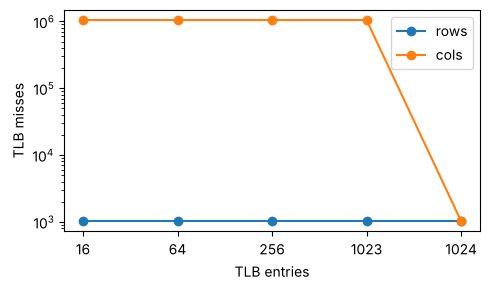

In [3]:
N, BASE = 1024, 0x1000_0000

def traverse(order, entries, mega=False):
    mem = vm.Memory(); pt = vm.PageTable(mem)
    if mega:
        pt.map_mega(BASE, 0x40000)
    else:
        for p in range(N * N * 4 // 4096):
            pt.map(BASE + 4096 * p, 0x40000 + p)
    m = vm.MMU(pt, vm.TLB(entries))
    if order == 'rows':
        for i in range(N):
            for j in range(N):
                m.access(BASE + 4 * (i * N + j))
    else:
        for j in range(N):
            for i in range(N):
                m.access(BASE + 4 * (i * N + j))
    return m

sizes = [16, 64, 256, 1023, 1024]
res = {o: [traverse(o, e).tlb.misses for e in sizes] for o in ('rows', 'cols')}
print(res)
print('megapage:', traverse('cols', 64, mega=True).tlb.misses, 'miss')
plt.figure(figsize=(5, 3))
for o, y in res.items():
    plt.plot(range(len(sizes)), y, marker='o', label=o)
plt.yscale('log'); plt.xticks(range(len(sizes)), sizes); plt.xlabel('TLB entries'); plt.ylabel('TLB misses'); plt.legend(); plt.tight_layout(); plt.show()

## Part 3 · Page-table memory

In [4]:
def table_pages(regions):
    return 1 + len({p >> 22 for s, e in regions for p in range(s, e, 4096)})

KiB, MiB = 1024, 1024 * 1024
dense = [(BASE, BASE + 4 * MiB)]
sparse = [(0x0001_0000, 0x0001_0000 + 64 * KiB), (0x1000_0000, 0x1000_0000 + 3 * MiB), (0x8000_0000 - 128 * KiB, 0x8000_0000)]
for name, r in (('dense 4 MiB', dense), ('Example 14-10.1', sparse)):
    n = table_pages(r)
    print(f'{name:16s}: {n} table pages = {4 * n} KiB (a flat table would be 4096 KiB)')

dense 4 MiB     : 2 table pages = 8 KiB (a flat table would be 4096 KiB)
Example 14-10.1 : 4 table pages = 16 KiB (a flat table would be 4096 KiB)


## Part 4 · Demand paging and replacement

In [5]:
def mmu_faults(refs, frames, policy):
    m = vm.MMU(vm.PageTable(vm.Memory()), vm.TLB(64), frames=frames, policy=policy)
    for p in refs:
        m.access(0x1000_0000 + 4096 * p)
    return m.faults

reuse = [1, 2, 3, 1, 4, 1, 5, 1, 2, 1, 3, 1, 4]
belady = [5, 3, 4, 1, 5, 3, 2, 5, 3, 4, 1, 2]
cyclic = list(range(10)) * 10
for name, refs in (('reuse', reuse), ('Belady', belady), ('cyclic 10', cyclic)):
    for fr in (3, 4, 9, 10):
        row = {p: mmu_faults(refs, fr, p) for p in ('fifo', 'clock', 'lru')}
        row['opt'] = vm.page_faults(refs, fr, 'opt')
        print(f'{name:9s} {fr:2d} frames: {row}')

reuse      3 frames: {'fifo': 10, 'clock': 9, 'lru': 8, 'opt': 7}
reuse      4 frames: {'fifo': 9, 'clock': 9, 'lru': 8, 'opt': 6}
reuse      9 frames: {'fifo': 5, 'clock': 5, 'lru': 5, 'opt': 5}
reuse     10 frames: {'fifo': 5, 'clock': 5, 'lru': 5, 'opt': 5}
Belady     3 frames: {'fifo': 9, 'clock': 9, 'lru': 10, 'opt': 7}
Belady     4 frames: {'fifo': 10, 'clock': 10, 'lru': 8, 'opt': 6}
Belady     9 frames: {'fifo': 5, 'clock': 5, 'lru': 5, 'opt': 5}
Belady    10 frames: {'fifo': 5, 'clock': 5, 'lru': 5, 'opt': 5}
cyclic 10  3 frames: {'fifo': 100, 'clock': 100, 'lru': 100, 'opt': 80}
cyclic 10  4 frames: {'fifo': 100, 'clock': 100, 'lru': 100, 'opt': 70}
cyclic 10  9 frames: {'fifo': 100, 'clock': 100, 'lru': 100, 'opt': 20}
cyclic 10 10 frames: {'fifo': 10, 'clock': 10, 'lru': 10, 'opt': 10}
